# Federated Self-Supervised Learning for Robust Time-Series Representations


This notebook compares two self-supervised objectives for unsupervised anomaly detection on multivariate time series in a federated learning setting.

**Setup**
- **Data:** 4 clients, each with 240 unlabeled training windows (64 steps × 3 channels). Every client has its own frequency, amplitude, trend and noise level (non-IID), and 10% of its training windows are contaminated with anomalies. The test set has 480 labeled windows (50% anomalous).
- **Objectives:** Masked Reconstruction and Contrastive Learning.
- **Federation:** 7 rounds, 4 local epochs per round. The server combines client weights with FedAvg.
- **Scoring:** Masked model → Reconstruction Error, and Contrastive model → Cosine distance to the nearest embedding in a reference bank of training windows. Evaluated with AUROC and AUPRC.

## 1. Imports and Experiment Configuration

In [1]:
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 7

# Seed every RNG used in the notebook so each run is reproducible
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Experiment configuration
N_CLIENTS = 4
WINDOW = 64
N_CHANNELS = 3
TRAIN_WINDOWS_PER_CLIENT = 240
TEST_WINDOWS_PER_CLIENT = 120
CONTAMINATION = 0.10
LOCAL_EPOCHS = 4
ROUNDS = 7
BATCH_SIZE = 64
LATENT_DIM = 32
LR = 1e-3

Device: cpu


## 2. Synthetic Data Generation

In [2]:
# Generate a normal multivariate time-series window with client-specific characteristics
def make_normal_window(client_id, length=WINDOW, channels=N_CHANNELS, rng=None, drift=0.0):
    rng = rng or np.random.default_rng()
    t = np.linspace(0, 1, length, endpoint=False)
    freq = [1.0, 1.6, 2.2, 0.7, 2.8, 1.3][client_id % 6]
    amp = [1.0, 0.7, 1.3, 0.9, 1.5, 0.6][client_id % 6]
    channels_out = []
    for c in range(channels):
        f = freq * (1 + 0.12 * c)
        phase = 0.4 * client_id + 0.7 * c
        signal = amp * np.sin(2 * np.pi * f * t + phase)
        signal += 0.35 * np.cos(2 * np.pi * (0.5 * f) * t + 0.3 * c)
        signal += (0.15 + 0.03 * client_id) * t
        signal += drift * t * np.sin(2 * np.pi * 0.5 * t)
        signal += rng.normal(0, 0.12 + 0.025 * client_id, size=length)
        channels_out.append(signal)
    return np.stack(channels_out, axis=-1).astype(np.float32)

In [3]:
# Inject a randomly selected point, segment, frequency, or noise anomaly into a time-series window
def inject_anomaly(x, rng):
    x = x.copy()
    kind = rng.choice(["spike", "segment", "frequency", "noise"])
    length, channels = x.shape
    if kind == "spike":
        idx = rng.integers(2, length - 2)
        channel = rng.integers(channels)
        x[idx, channel] += rng.choice([-1, 1]) * rng.uniform(2.5, 4.5)
    elif kind == "segment":
        start = rng.integers(0, length // 2)
        end = min(length, start + rng.integers(8, 20))
        x[start:end] += rng.choice([-1, 1]) * rng.uniform(1.2, 2.5)
    elif kind == "frequency":
        t = np.linspace(0, 1, length, endpoint=False)
        channel = rng.integers(channels)
        x[:, channel] = 1.4 * np.sin(2 * np.pi * rng.uniform(3.0, 5.0) * t)
        x[:, channel] += rng.normal(0, 0.1, length)
    else:
        start = rng.integers(0, length - 8)
        end = min(length, start + rng.integers(8, 24))
        x[start:end] += rng.normal(0, 1.2, size=(end - start, channels))
    return x.astype(np.float32)

In [4]:
# Create non-IID client training sets and a separate labeled test set for evaluation
def build_client_data(n_train=TRAIN_WINDOWS_PER_CLIENT, n_test=TEST_WINDOWS_PER_CLIENT,
                      contamination=CONTAMINATION, seed=SEED):
    rng = np.random.default_rng(seed)
    clients, test_x, test_y, test_client = [], [], [], []
    for client_id in range(N_CLIENTS):
        train = np.stack([
            make_normal_window(client_id, rng=rng) for _ in range(n_train)
        ])
        n_contaminated = int(n_train * contamination)
        if n_contaminated:
            ids = rng.choice(n_train, n_contaminated, replace=False)
            for idx in ids:
                train[idx] = inject_anomaly(train[idx], rng)
        clients.append(torch.tensor(train, dtype=torch.float32))

        n_normal = n_test // 2
        n_anomaly = n_test - n_normal
        normals = [
            make_normal_window(client_id, rng=rng) for _ in range(n_normal)
        ]
        anomalies = [
            inject_anomaly(make_normal_window(client_id, rng=rng), rng)
            for _ in range(n_anomaly)
        ]
        test_x.extend(normals + anomalies)
        test_y.extend([0] * len(normals) + [1] * len(anomalies))
        test_client.extend([client_id] * (len(normals) + len(anomalies)))

    return (
        clients,
        torch.tensor(np.stack(test_x), dtype=torch.float32),
        np.asarray(test_y),
        np.asarray(test_client),
    )

In [5]:
client_train, X_test, y_test, test_client_ids = build_client_data()
print("Client Training Shapes:", [tuple(x.shape) for x in client_train])
print("Test Shape:", tuple(X_test.shape))
print("Test Anomaly Prevalence:", y_test.mean())

Client Training Shapes: [(240, 64, 3), (240, 64, 3), (240, 64, 3), (240, 64, 3)]
Test Shape: (480, 64, 3)
Test Anomaly Prevalence: 0.5


## 3. Inspect the Synthetic Data

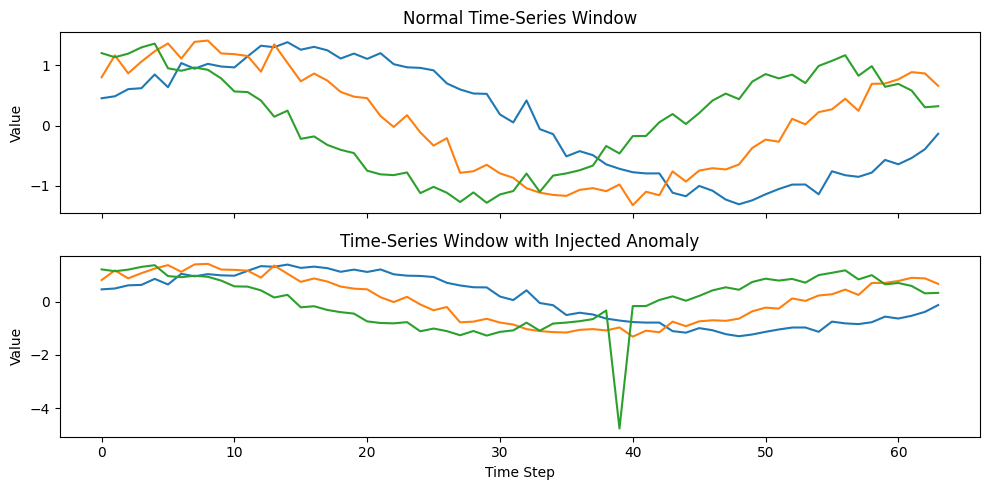

In [6]:
rng = np.random.default_rng(SEED + 99)
normal_example = make_normal_window(0, rng=rng)
anomaly_example = inject_anomaly(normal_example, rng)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(normal_example)
axes[0].set_title("Normal Time-Series Window")
axes[0].set_ylabel("Value")
axes[1].plot(anomaly_example)
axes[1].set_title("Time-Series Window with Injected Anomaly")
axes[1].set_ylabel("Value")
axes[1].set_xlabel("Time Step")
plt.tight_layout()

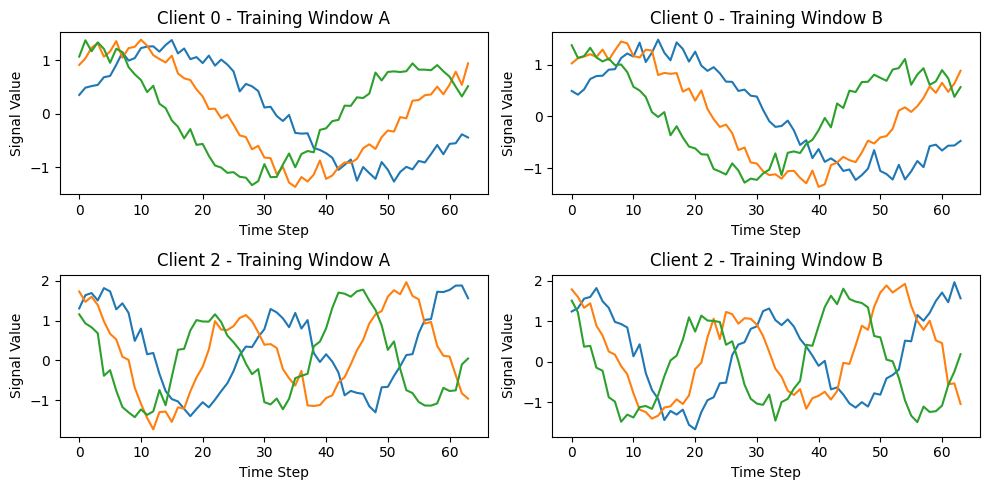

In [7]:
# Training data for the first and third clients
clients_to_plot = [0, 2]
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for row, client_id in enumerate(clients_to_plot):
    train_data = client_train[client_id].numpy()
    normal_train = train_data[0]
    another_train = train_data[24]
    axes[row, 0].plot(normal_train)
    axes[row, 0].set_title(
        f"Client {client_id} - Training Window A"
    )

    axes[row, 0].set_xlabel("Time Step")
    axes[row, 0].set_ylabel("Signal Value")
    axes[row, 1].plot(another_train)
    axes[row, 1].set_title(
        f"Client {client_id} - Training Window B"
    )

    axes[row, 1].set_xlabel("Time Step")
    axes[row, 1].set_ylabel("Signal Value")

plt.tight_layout()
plt.show()

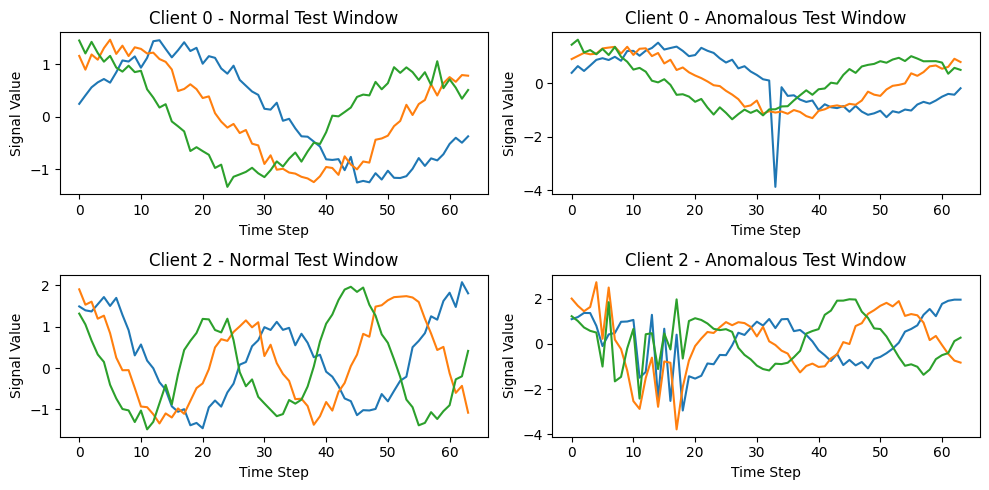

In [8]:
# Testing data for the first and third clients
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for row, client_id in enumerate(clients_to_plot):
    client_indices = np.where(test_client_ids == client_id)[0]
    normal_idx = client_indices[np.where(y_test[client_indices] == 0)[0][0]]
    anomaly_idx = client_indices[np.where(y_test[client_indices] == 1)[0][0]]

    axes[row, 0].plot(X_test[normal_idx].numpy())
    axes[row, 0].set_title(f"Client {client_id} - Normal Test Window")

    axes[row, 1].plot(X_test[anomaly_idx].numpy())
    axes[row, 1].set_title(f"Client {client_id} - Anomalous Test Window")

    for col in range(2):
        axes[row, col].set_xlabel("Time Step")
        axes[row, col].set_ylabel("Signal Value")

plt.tight_layout()
plt.show()

## 4. Model Architectures

In [9]:
# Encode a multivariate time-series window into a fixed-length representation
class Encoder(nn.Module):
    def __init__(self, channels=N_CHANNELS, latent_dim=LATENT_DIM, width=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(channels, width, kernel_size=5, padding=2),
            nn.GELU(),
            nn.Conv1d(width, width, kernel_size=5, padding=2, stride=2),
            nn.GELU(),
            nn.Conv1d(width, width, kernel_size=3, padding=1, stride=2),
            nn.GELU(),
        )
        self.proj = nn.Linear(width, latent_dim)

    def forward(self, x):
        h = self.net(x.transpose(1, 2))
        h = h.mean(dim=-1)
        return self.proj(h)

In [10]:
# Encode partially masked windows and reconstruct the complete input sequence
class MaskedReconstructionModel(nn.Module):
    def __init__(self, channels=N_CHANNELS, latent_dim=LATENT_DIM, width=32):
        super().__init__()
        self.encoder = Encoder(channels, latent_dim, width)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.GELU(),
            nn.Linear(128, WINDOW * channels),
        )
        self.channels = channels

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z).view(
            x.shape[0], x.shape[1], self.channels
        )
        return reconstruction, z

In [11]:
# Learn time-series representations using an encoder and a contrastive projection head
class ContrastiveModel(nn.Module):
    def __init__(self, channels=N_CHANNELS, latent_dim=LATENT_DIM, width=32):
        super().__init__()
        self.encoder = Encoder(channels, latent_dim, width)
        self.projector = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.ReLU(),
            nn.Linear(latent_dim, latent_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        projection = F.normalize(self.projector(z), dim=-1)
        return z, projection

## 5. Self-Supervised Augmentations and Losses

In [12]:
# Create a contrastive view using mild amplitude scaling and additive Gaussian noise
def augment(x):
    scale = torch.empty((x.shape[0], 1, 1), device=x.device).uniform_(0.8, 1.2)
    noise = torch.randn_like(x) * 0.05
    return x * scale + noise

In [13]:
# Compute reconstruction loss over randomly masked temporal patches
def masked_reconstruction_loss(model, x, mask_ratio=0.4):
    batch_size, length, channels = x.shape
    mask = torch.zeros((batch_size, length, 1), device=x.device)
    patch_length = max(4, int(length * mask_ratio / 4))
    n_patches = max(1, int(length * mask_ratio / patch_length))
    for batch_idx in range(batch_size):
        starts = torch.randperm(
            max(1, length - patch_length + 1), device=x.device
        )[:n_patches]
        for start in starts:
            mask[batch_idx, start:min(length, start + patch_length)] = 1
    masked_input = x * (1 - mask)
    reconstruction, _ = model(masked_input)
    squared_error = (reconstruction - x) ** 2
    return (squared_error * mask).sum() / (mask.sum() * channels + 1e-8)

In [14]:
# Compute the normalized temperature-scaled cross-entropy loss for paired views
def nt_xent(z1, z2, temperature=0.2):
    representations = torch.cat([z1, z2], dim=0)
    similarity = representations @ representations.T / temperature
    n = z1.shape[0]
    similarity.fill_diagonal_(-1e9)
    targets = torch.cat([
        torch.arange(n, 2 * n),
        torch.arange(0, n),
    ]).to(z1.device)
    return F.cross_entropy(similarity, targets)

## 6. Model Initialization and Local Training

In [15]:
# Initialize the model corresponding to the selected self-supervised objective
def make_model(method="masked", width=32):
    if method == "masked":
        return MaskedReconstructionModel(width=width).to(DEVICE)
    if method == "contrastive":
        return ContrastiveModel(width=width).to(DEVICE)
    raise ValueError(f"Unknown method: {method}")

In [16]:
# Train one client's model on unlabeled local time-series windows
def train_local(model, data, method, epochs=LOCAL_EPOCHS, lr=LR, batch_size=BATCH_SIZE):
    model.train()
    loader = DataLoader(TensorDataset(data), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        for (x,) in loader:
            x = x.to(DEVICE)
            optimizer.zero_grad()
            if method == "masked":
                loss = masked_reconstruction_loss(model, x)
            else:
                _, projection1 = model(augment(x))
                _, projection2 = model(augment(x))
                loss = nt_xent(projection1, projection2)
            loss.backward()
            optimizer.step()
    return model

## 7. Federated Aggregation

In [17]:
# Aggregate client model parameters using weighted averaging
def aggregate_states(states, weights, strategy="fedavg"):
    aggregated = {}
    for key in states[0].keys():
        stacked = torch.stack([state[key].float() for state in states], dim=0)
        if strategy == "fedavg":
            weight_tensor = torch.tensor(weights, dtype=stacked.dtype, device=stacked.device)
            weight_tensor = weight_tensor / weight_tensor.sum()
            shape = [len(weights)] + [1] * (stacked.ndim - 1)
            value = (stacked * weight_tensor.view(*shape)).sum(dim=0)
        else:
            raise ValueError(f"Unknown aggregation strategy: {strategy}")
        aggregated[key] = value.to(states[0][key].dtype)
    return aggregated

In [18]:
# Train client models over communication rounds and aggregate their parameters on a server
def federated_train(method="masked", strategy="fedavg", rounds=ROUNDS, width=32,
                    profile_weighting=False, verbose=True, client_data=None):
    client_data = client_train if client_data is None else client_data
    global_model = make_model(method, width)
    client_sizes = np.array([len(data) for data in client_data], dtype=float)

    for round_idx in range(rounds):
        client_states, profiles = [], []
        for data in client_data:
            local_model = make_model(method, width)
            local_model.load_state_dict(global_model.state_dict())
            train_local(local_model, data, method)
            client_states.append(copy.deepcopy(local_model.state_dict()))
            if profile_weighting:
                profile = torch.cat([
                    data.mean(dim=1).mean(dim=0),
                    data.std(dim=1).mean(dim=0),
                ])
                profiles.append(profile.numpy())

        weights = client_sizes.copy()
        if profile_weighting:
            profile_matrix = np.stack(profiles)
            center = profile_matrix.mean(axis=0)
            distances = np.linalg.norm(profile_matrix - center, axis=1)
            similarity_weights = 1.0 / (1.0 + distances)
            weights *= similarity_weights

        global_model.load_state_dict(
            aggregate_states(client_states, weights, strategy=strategy)
        )
        if verbose:
            print(f"Round {round_idx + 1}/{rounds} completed")

    return global_model

## 8. Anomaly Scoring and Evaluation

In [19]:
# Assign anomaly scores using reconstruction error or distance from a latent reference bank
def score_model(model, method, X, reference=None, batch_size=128):
    model.eval()
    scores = []

    if method == "contrastive":
        if reference is None:
            raise ValueError("Contrastive scoring requires a reference bank.")
        reference_embeddings = []
        with torch.no_grad():
            for start in range(0, len(reference), batch_size):
                reference_batch = reference[start:start + batch_size].to(DEVICE)
                embeddings = model.encoder(reference_batch)
                reference_embeddings.append(F.normalize(embeddings, dim=-1).cpu())
        reference_embeddings = torch.cat(reference_embeddings, dim=0)

    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            x = X[start:start + batch_size].to(DEVICE)
            if method == "masked":
                reconstruction, _ = model(x)
                batch_scores = ((reconstruction - x) ** 2).mean(dim=(1, 2))
            else:
                embeddings = F.normalize(model.encoder(x), dim=-1).cpu()
                batch_scores = 1 - (
                    embeddings @ reference_embeddings.T
                ).max(dim=1).values
            scores.extend(batch_scores.cpu().numpy().tolist())

    return np.asarray(scores)

In [20]:
# Evaluate anomaly scores using AUROC, AUPRC, and average scores by test class
def evaluate_model(model, method, X_test, y_test, reference):
    scores = score_model(model, method, X_test, reference=reference)
    metrics = {
        "AUROC": roc_auc_score(y_test, scores),
        "AUPRC": average_precision_score(y_test, scores),
        "Mean_Normal_Score": float(scores[y_test == 0].mean()),
        "Mean_Anomaly_Score": float(scores[y_test == 1].mean()),
    }
    return metrics, scores

## 9. Baseline Comparison

In [21]:
# Train and evaluate each objective and aggregation strategy, recording performance and runtime
def run_baseline_comparison(methods=("masked", "contrastive"),
                            strategies="fedavg"):
    rows = []
    trained_models = {}
    reference = torch.cat(client_train)

    for method in methods:
          set_seed(SEED)
          start_time = time.time()
          model = federated_train(
              method=method,
              strategy=strategies,
              rounds=ROUNDS,
              width=32,
              verbose=False,
            )
          elapsed = time.time() - start_time
          metrics, scores = evaluate_model(model, method, X_test, y_test, reference)
          rows.append({
                "method": method,
                "aggregation": strategies,
                **metrics,
                "training_seconds": elapsed,
                "parameters": sum(parameter.numel() for parameter in model.parameters()),
          })
          trained_models[(method, strategies)] = (model, scores)
          print(f"Completed: method={method}, aggregation={strategies}")

    return pd.DataFrame(rows).sort_values("AUROC", ascending=False), trained_models

In [22]:
results_df, trained_models = run_baseline_comparison()
results_df

Completed: method=masked, aggregation=fedavg
Completed: method=contrastive, aggregation=fedavg


,method,aggregation,AUROC,AUPRC,Mean_Normal_Score,Mean_Anomaly_Score,training_seconds,parameters
1,contrastive,fedavg,0.977908,0.979994,0.000110,0.002047,9.609056,11936
0,masked,fedavg,0.788229,0.775059,0.424469,0.782904,15.788552,38816


## 10. Plot Anomaly-Score Distributions

In [23]:
# Plot normal and anomalous test-score distributions for each self-supervised method
def plot_score_distributions(trained_models, y_test, aggregation="fedavg"):
    methods = sorted({key[0] for key in trained_models if key[1] == aggregation})
    fig, axes = plt.subplots(1, len(methods), figsize=(6 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
    for axis, method in zip(axes, methods):
        _, scores = trained_models[(method, aggregation)]
        axis.hist(scores[y_test == 0], bins=25, alpha=0.65, label="Normal")
        axis.hist(scores[y_test == 1], bins=25, alpha=0.65, label="Anomaly")
        axis.set_title(f"{method} / {aggregation}")
        axis.set_xlabel("Anomaly Score")
        axis.set_ylabel("Count")
        axis.legend()
    plt.tight_layout()
    return fig

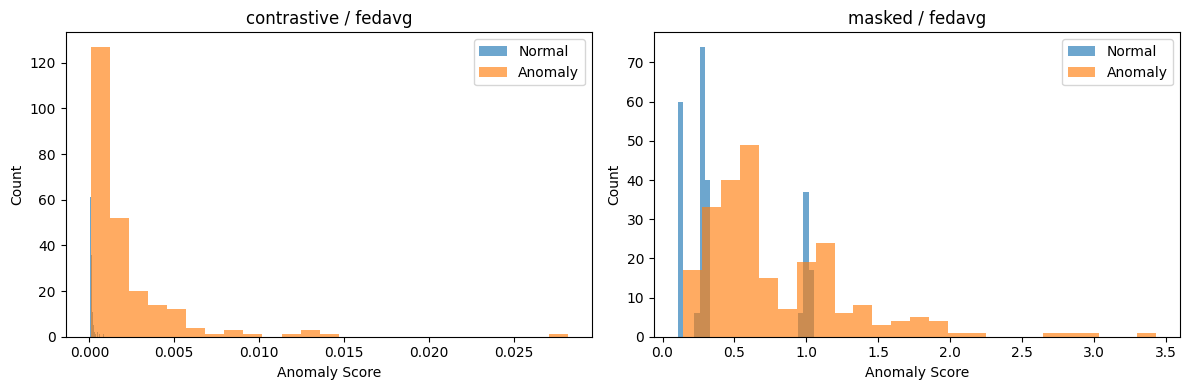

In [24]:
plot_score_distributions(trained_models, y_test)
plt.show()